# Image Preprocessing and Facial Recognition

**Member 2 - David Shumbusho**

This notebook is the first security checkpoint of the User Identity and Product Recommendation System: a face must belong to an authorized group member before the product recommendation model may run.

**Pipeline**

1. Load each member's photos (neutral, smiling, surprised) from `datasets/images/<identity>/`. JPEG and HEIC are both supported.
2. Detect the face with OpenCV's pretrained **YuNet** detector and align it to a 112x112 crop using the eye, nose and mouth landmarks.
3. Augment every aligned crop with **rotation, horizontal flip, grayscale and brightness**.
4. Extract a 128-dimensional **SFace face embedding** (pretrained OpenCV model) for every crop and save it to `datasets/image_features.csv`.
5. Train a **Logistic Regression** classifier on the embeddings to name the member.
6. Accept a face only when its **cosine similarity** to that member's enrolled faces reaches a threshold, so strangers are rejected.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from facial_recognition import (
    FEATURES_PATH,
    IMAGE_DIR,
    MODEL_PATH,
    augment_face_images,
    discover_images,
    discover_unauthorized_images,
    expression_from_name,
    load_face_crop,
    load_image,
    train_face_model,
    verify_face,
)

pd.set_option("display.precision", 3)

## 1. Collected images

Identity labels come from the folder names (`Allan`, `David`, `Nazira`, `Shamila`). The same labels are used for the audio dataset.

In [2]:
image_paths = discover_images(IMAGE_DIR)
inventory = pd.DataFrame(
    [
        {"identity": identity, "image": path.name, "expression": expression_from_name(path), "format": path.suffix.lower()}
        for identity, path in image_paths
    ]
)
display(inventory.pivot(index="identity", columns="expression", values="image"))

expression,neutral,smiling,surprised
identity,,,
Allan,Allan_neutral.jpg,Allan_smiling.jpg,Allan_surprised.jpg
David,David_neutral.JPG,David_smiling.JPG,David_surprised.HEIC
Nazira,Nazira_neutral.HEIC,Nazira_smiling.HEIC,Nazira_surprised.jpeg
Shamila,Shamila_neutral.jpeg,Shamila_smiling.jpeg,Shamila_surprised.jpeg


## 2. Sample pictures of each member

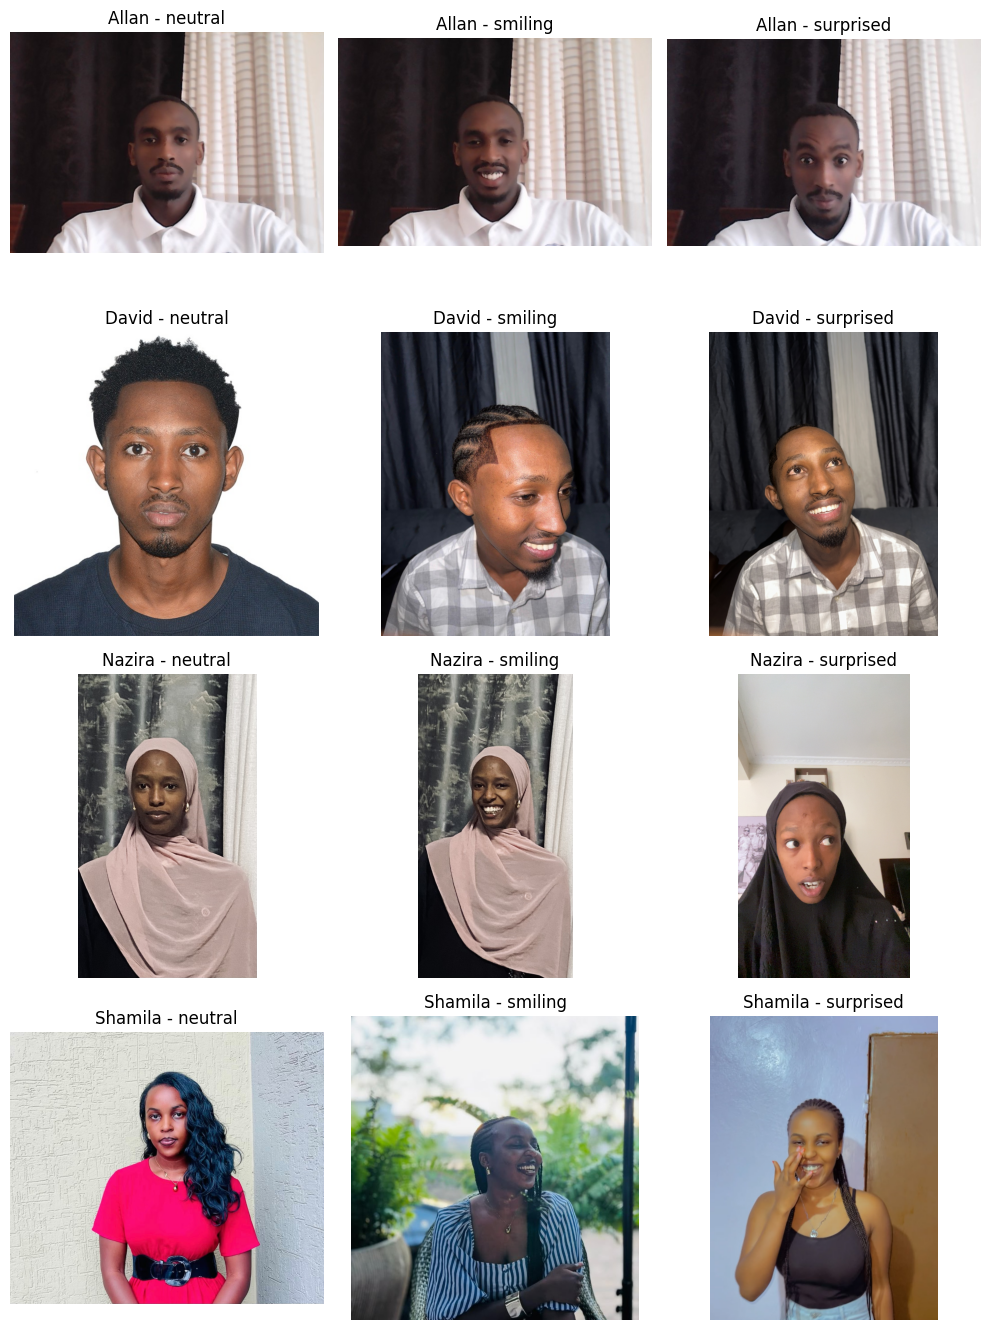

In [3]:
identities = sorted(inventory["identity"].unique())
expressions = ["neutral", "smiling", "surprised"]
fig, axes = plt.subplots(len(identities), 3, figsize=(10, 3.4 * len(identities)))
for row, identity in enumerate(identities):
    for col, expression in enumerate(expressions):
        path = next(p for i, p in image_paths if i == identity and expression_from_name(p) == expression)
        axes[row, col].imshow(load_image(path))
        axes[row, col].set_title(f"{identity} - {expression}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## 3. Face detection and alignment

YuNet finds the face and its five landmarks. The crop is rotated and scaled so the eyes always sit in the same place, which makes the embeddings comparable across photos.

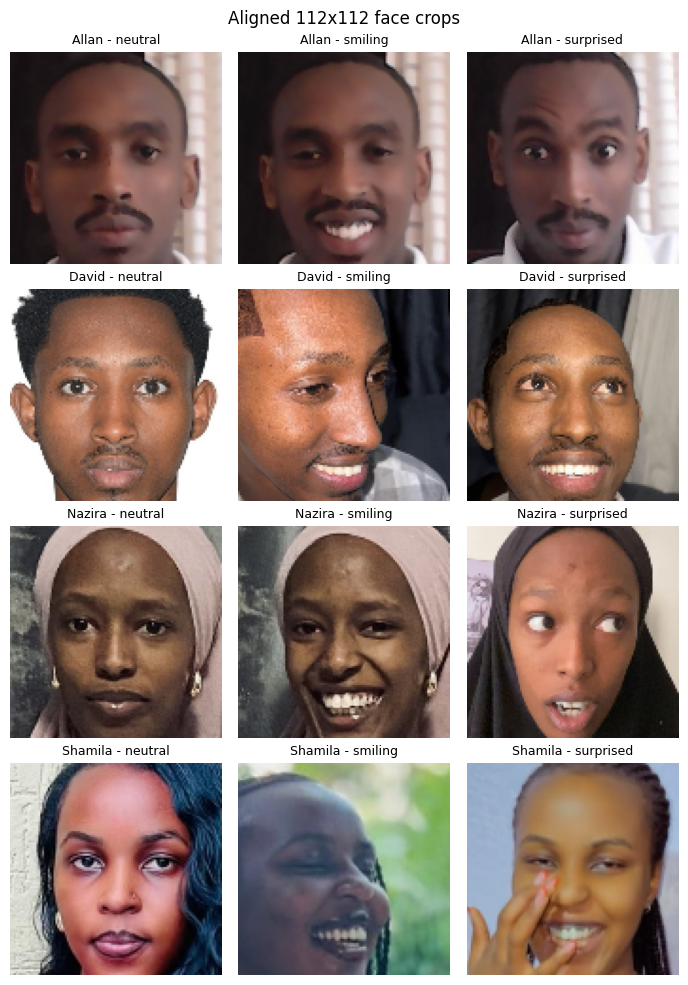

In [4]:
crops = {path: load_face_crop(path) for _, path in image_paths}
fig, axes = plt.subplots(len(identities), 3, figsize=(7, 2.5 * len(identities)))
for row, identity in enumerate(identities):
    for col, expression in enumerate(expressions):
        path = next(p for i, p in image_paths if i == identity and expression_from_name(p) == expression)
        axes[row, col].imshow(crops[path])
        axes[row, col].set_title(f"{identity} - {expression}", fontsize=9)
        axes[row, col].axis("off")
plt.suptitle("Aligned 112x112 face crops")
plt.tight_layout()
plt.show()

## 4. Augmentations (per member)

Every original crop gets four augmentations: rotation (10 degrees), horizontal flip, grayscale and a brightness increase. With 12 originals this gives 60 training samples.

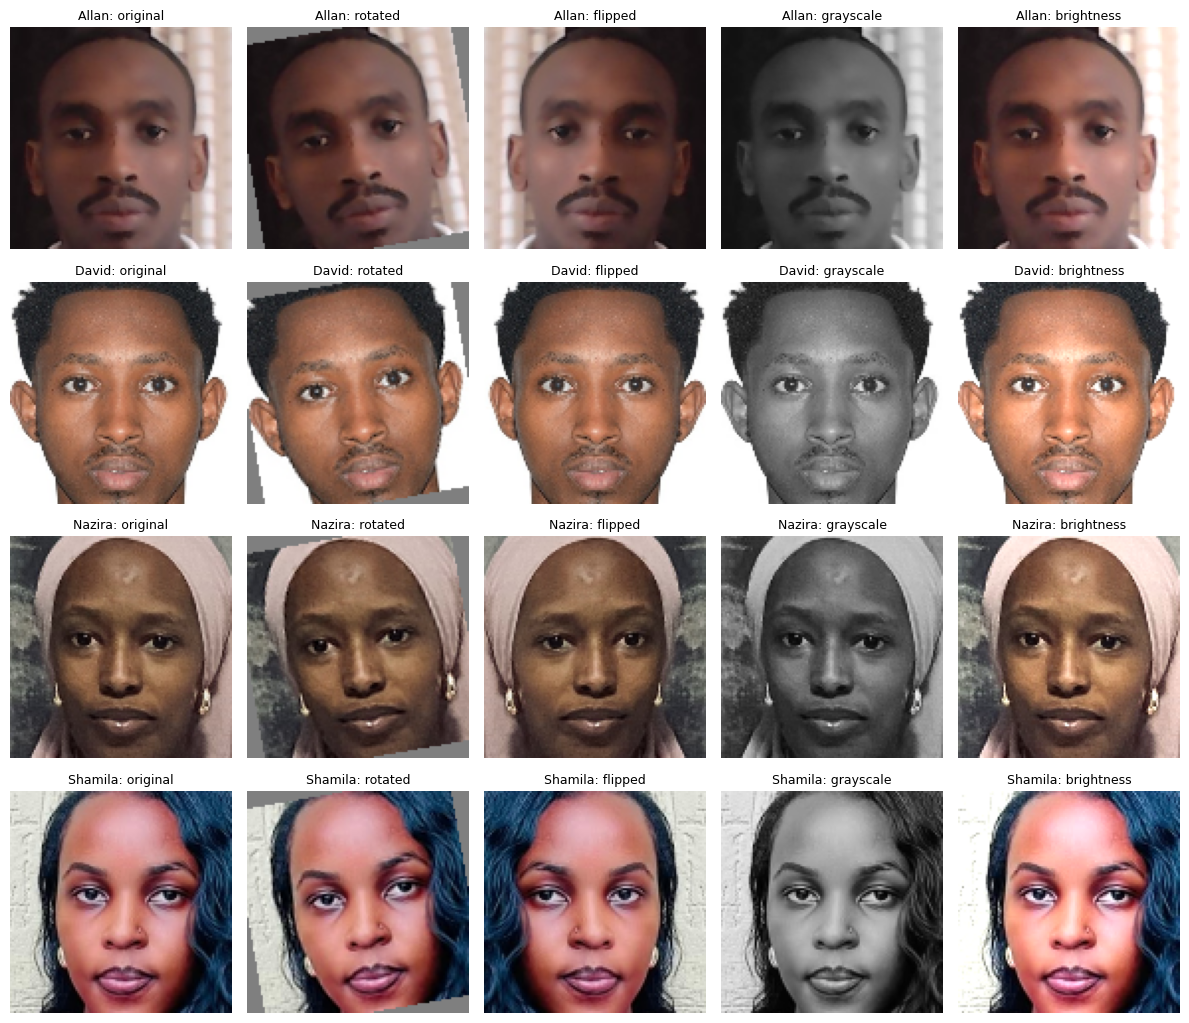

In [5]:
fig, axes = plt.subplots(len(identities), 5, figsize=(12, 2.6 * len(identities)))
for row, identity in enumerate(identities):
    path = next(p for i, p in image_paths if i == identity)
    for col, (name, image) in enumerate(augment_face_images(crops[path]).items()):
        axes[row, col].imshow(image)
        axes[row, col].set_title(f"{identity}: {name}", fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## 5. Feature extraction, evaluation and training

`train_face_model()` extracts the embeddings, writes `image_features.csv`, evaluates the model without leakage and saves the final model.

* **Identification (leave-one-image-out):** each photo is predicted by a model trained only on the *other* photos and their augmentations.
* **Impostor test (leave-one-person-out):** each member is removed from training and their photos are presented as a stranger. The photos in `datasets/unauthorized_images/` are also tested. All of these attempts must be rejected.

In [6]:
evaluation = train_face_model(return_details=True)
display(pd.Series(evaluation["metrics"], name="score").to_frame())
print(f"Feature table: {FEATURES_PATH.relative_to(ROOT)}")
print(f"Saved model:   {MODEL_PATH.relative_to(ROOT)}")

,score
accuracy,1.000
precision_macro,1.000
recall_macro,1.000
f1_macro,1.000
log_loss,0.173
false_reject_rate,0.000
false_accept_rate,0.000
verification_accuracy,1.000


Feature table: datasets/image_features.csv
Saved model:   models/face_model.pkl


In [7]:
features = pd.read_csv(FEATURES_PATH)
embedding_columns = [c for c in features.columns if c.startswith("emb_")]
print("Shape:", features.shape, "| embedding dimensions:", len(embedding_columns))
display(features.groupby(["identity", "augmentation"]).size().unstack())
display(features.iloc[:5, :10])

Shape: (60, 132) | embedding dimensions: 128


augmentation,brightness,flipped,grayscale,original,rotated
identity,,,,,
Allan,3,3,3,3,3
David,3,3,3,3,3
Nazira,3,3,3,3,3
Shamila,3,3,3,3,3


,identity,source_image,expression,augmentation,emb_000,emb_001,emb_002,emb_003,emb_004,emb_005
0,Allan,datasets/images/Allan/Allan_neutral.jpg,neutral,original,-0.110,-0.124,0.065,0.168,-0.039,0.101
1,Allan,datasets/images/Allan/Allan_neutral.jpg,neutral,rotated,-0.135,-0.168,0.098,0.141,-0.058,0.005
2,Allan,datasets/images/Allan/Allan_neutral.jpg,neutral,flipped,-0.118,-0.107,0.086,0.178,-0.081,0.073
3,Allan,datasets/images/Allan/Allan_neutral.jpg,neutral,grayscale,-0.125,-0.124,0.073,0.140,-0.023,0.098
4,Allan,datasets/images/Allan/Allan_neutral.jpg,neutral,brightness,-0.119,-0.125,0.073,0.171,-0.034,0.101


### Embedding space

A 2-D PCA projection of all 60 embeddings. Each member forms a separate cluster, including their augmented copies.

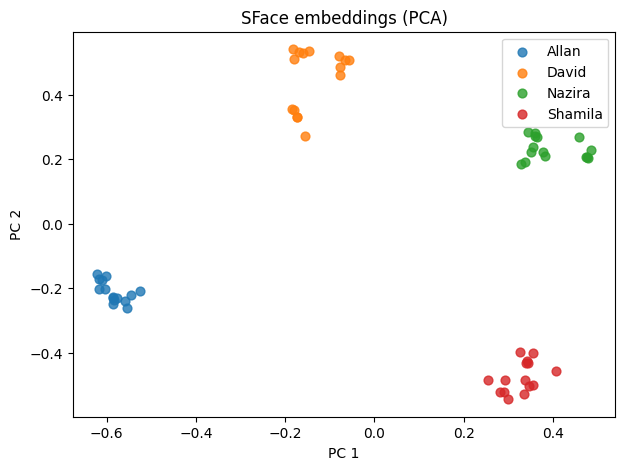

In [8]:
points = PCA(n_components=2, random_state=42).fit_transform(features[embedding_columns])
fig, ax = plt.subplots(figsize=(7, 5))
for identity in identities:
    mask = features["identity"] == identity
    ax.scatter(points[mask, 0], points[mask, 1], label=identity, s=40, alpha=0.8)
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_title("SFace embeddings (PCA)")
ax.legend()
plt.show()

## 6. Evaluation results

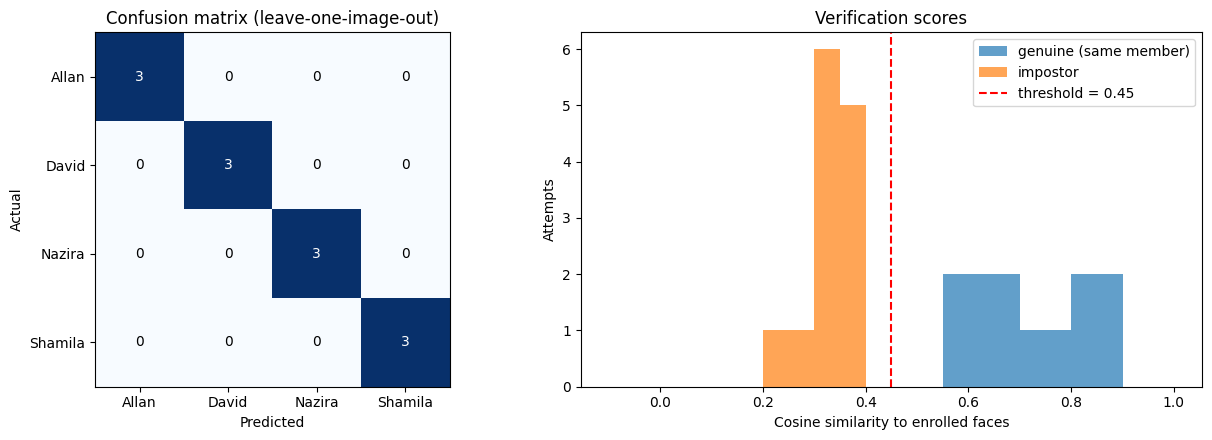

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

matrix = evaluation["confusion_matrix"]
classes = evaluation["classes"]
axes[0].imshow(matrix, cmap="Blues")
axes[0].set_xticks(range(len(classes)), classes)
axes[0].set_yticks(range(len(classes)), classes)
for i in range(len(classes)):
    for j in range(len(classes)):
        axes[0].text(j, i, matrix[i, j], ha="center", va="center",
                     color="white" if matrix[i, j] > matrix.max() / 2 else "black")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_title("Confusion matrix (leave-one-image-out)")

impostors = evaluation["impostor_attempts"]
bins = np.linspace(-0.1, 1.0, 23)
axes[1].hist(evaluation["genuine_scores"], bins=bins, alpha=0.7, label="genuine (same member)")
axes[1].hist(impostors["similarity"], bins=bins, alpha=0.7, label="impostor")
axes[1].axvline(evaluation["threshold"], color="red", linestyle="--", label=f"threshold = {evaluation['threshold']}")
axes[1].set_xlabel("Cosine similarity to enrolled faces")
axes[1].set_ylabel("Attempts")
axes[1].set_title("Verification scores")
axes[1].legend()
plt.tight_layout()
plt.show()

In [10]:
display(impostors[["probe", "type", "predicted_identity", "similarity", "authorized"]])

,probe,type,predicted_identity,similarity,authorized
0,datasets/images/Allan/Allan_neutral.jpg,held-out member,David,0.308,False
1,datasets/images/Allan/Allan_smiling.jpg,held-out member,David,0.395,False
2,datasets/images/Allan/Allan_surprised.jpg,held-out member,David,0.367,False
3,datasets/images/David/David_neutral.JPG,held-out member,Nazira,0.359,False
4,datasets/images/David/David_smiling.JPG,held-out member,Allan,0.383,False
5,datasets/images/David/David_surprised.HEIC,held-out member,Nazira,0.321,False
6,datasets/images/Nazira/Nazira_neutral.HEIC,held-out member,David,0.340,False
7,datasets/images/Nazira/Nazira_smiling.HEIC,held-out member,Shamila,0.355,False
8,datasets/images/Nazira/Nazira_surprised.jpeg,held-out member,Shamila,0.302,False
9,datasets/images/Shamila/Shamila_neutral.jpeg,held-out member,Nazira,0.324,False


## 7. Verify a face (authorized vs unauthorized)

`verify_face(image_path)` is the function the command-line app calls. It returns `identity` (None when rejected), `authorized`, `confidence` (classifier probability), `similarity` and `reason`.

datasets/images/David/David_neutral.JPG -> {'identity': 'David', 'authorized': True, 'confidence': 0.9612058740481259, 'similarity': 0.9999999403953552, 'reason': 'verified'}
datasets/unauthorized_images/unknown_astronaut.png -> {'identity': None, 'authorized': False, 'confidence': 0.4496261120513439, 'similarity': 0.21607346832752228, 'reason': 'similarity_below_threshold'}


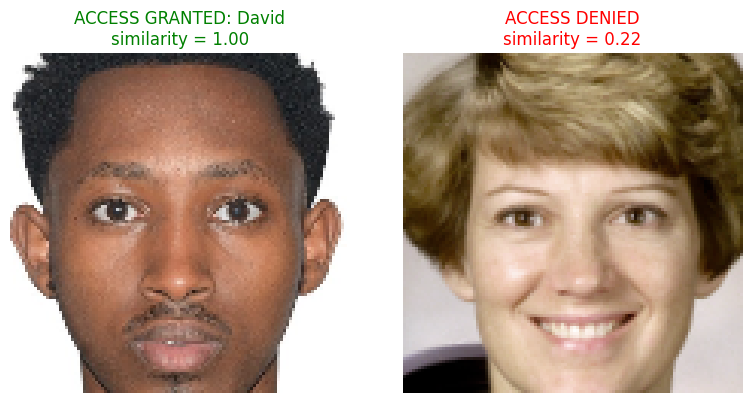

In [11]:
demo_paths = [image_paths[3][1]] + discover_unauthorized_images()
fig, axes = plt.subplots(1, len(demo_paths), figsize=(4 * len(demo_paths), 4))
for axis, path in zip(np.atleast_1d(axes), demo_paths):
    result = verify_face(path)
    print(path.relative_to(ROOT), "->", result)
    axis.imshow(load_face_crop(path))
    verdict = f"ACCESS GRANTED: {result['identity']}" if result["authorized"] else "ACCESS DENIED"
    axis.set_title(f"{verdict}\nsimilarity = {result['similarity']:.2f}",
                   color="green" if result["authorized"] else "red")
    axis.axis("off")
plt.tight_layout()
plt.show()

## 8. Conclusions and limitations

* Pretrained SFace embeddings separate the four members clearly. Held-out photos of the same person score well above the threshold, while other people stay well below it, so new photos of members are accepted and strangers are rejected.
* An earlier HOG + SVM baseline memorised the training photos: held-out photos scored 0.20 to 0.33 against a 0.65 threshold, so a fresh photo of a real member would have been denied. Switching to pretrained embeddings fixed this.
* The dataset is still small (3 photos per person, 1 external unknown face). The metrics show that the approach works, not that it is production-ready. More photos with different lighting and backgrounds would make the threshold more reliable.
* There is no liveness or anti-spoofing check, so a printed photo of a member could pass. This is acceptable for the assignment simulation but not for real security.